# Day 4 — Exploratory Data Analysis (EDA)

## Objective
Explore the cleaned mutual fund datasets to identify patterns,
trends, relationships, anomalies, and useful business insights.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully")

Libraries imported successfully


In [4]:
# Load cleaned datasets

nav_df = pd.read_csv(
    "../data/processed/nav_history_cleaned.csv"
)

transactions_df = pd.read_csv(
    "../data/processed/investor_transactions_cleaned.csv"
)

performance_df = pd.read_csv(
    "../data/processed/scheme_performance_cleaned.csv"
)


# Load raw datasets

fund_master_df = pd.read_csv(
    "../data/raw/1788499983024-b042c300-01_fund_master.csv"
)

benchmark_df = pd.read_csv(
    "../data/raw/1788499982615-f9647ab2-10_benchmark_indices.csv"
)

aum_df = pd.read_csv(
    "../data/raw/1788499984134-b0cbf625-03_aum_by_fund_house.csv"
)

sip_df = pd.read_csv(
    "../data/raw/1788499984405-d702a6c6-04_monthly_sip_inflows.csv"
)

category_inflows_df = pd.read_csv(
    "../data/raw/1788499984721-4b860901-05_category_inflows.csv"
)

folio_df = pd.read_csv(
    "../data/raw/1788499985036-da4a0c4a-06_industry_folio_count.csv"
)


print("All EDA datasets loaded successfully")

All EDA datasets loaded successfully


In [5]:
datasets = {
    "NAV History": nav_df,
    "Transactions": transactions_df,
    "Performance": performance_df,
    "Fund Master": fund_master_df,
    "Benchmark": benchmark_df,
    "AUM": aum_df,
    "SIP": sip_df,
    "Category Inflows": category_inflows_df,
    "Folio Count": folio_df
}

for name, df in datasets.items():
    print(
        f"{name:<20} | "
        f"Rows: {df.shape[0]:>6} | "
        f"Columns: {df.shape[1]:>2}"
    )

NAV History          | Rows:  46000 | Columns:  3
Transactions         | Rows:  32778 | Columns: 13
Performance          | Rows:     40 | Columns: 19
Fund Master          | Rows:     40 | Columns: 15
Benchmark            | Rows:   8050 | Columns:  3
AUM                  | Rows:     90 | Columns:  5
SIP                  | Rows:     48 | Columns:  6
Category Inflows     | Rows:    144 | Columns:  3
Folio Count          | Rows:     21 | Columns:  6


In [6]:
for name, df in datasets.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(df.dtypes)


NAV History
amfi_code      int64
date          object
nav          float64
dtype: object

Transactions
investor_id            object
transaction_date       object
amfi_code               int64
transaction_type       object
amount_inr              int64
state                  object
city                   object
city_tier              object
age_group              object
gender                 object
annual_income_lakh    float64
payment_mode           object
kyc_status             object
dtype: object

Performance
amfi_code               int64
scheme_name            object
fund_house             object
category               object
plan                   object
return_1yr_pct        float64
return_3yr_pct        float64
return_5yr_pct        float64
benchmark_3yr_pct     float64
alpha                 float64
beta                  float64
sharpe_ratio          float64
sortino_ratio         float64
std_dev_ann_pct       float64
max_drawdown_pct      float64
aum_crore               int64

In [7]:
for name, df in datasets.items():

    missing = df.isnull().sum()

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(missing[missing > 0])


NAV History
Series([], dtype: int64)

Transactions
Series([], dtype: int64)

Performance
Series([], dtype: int64)

Fund Master
Series([], dtype: int64)

Benchmark
Series([], dtype: int64)

AUM
Series([], dtype: int64)

SIP
yoy_growth_pct    12
dtype: int64

Category Inflows
Series([], dtype: int64)

Folio Count
Series([], dtype: int64)


In [8]:
fund_house_counts = (
    fund_master_df["fund_house"]
    .value_counts()
    .reset_index()
)

fund_house_counts.columns = [
    "fund_house",
    "fund_count"
]

display(fund_house_counts)

,fund_house,fund_count
0,SBI Mutual Fund,5
1,HDFC Mutual Fund,5
2,ICICI Prudential MF,5
3,Nippon India MF,5
4,Kotak Mahindra MF,4
5,Axis Mutual Fund,4
6,Aditya Birla Sun Life MF,3
7,UTI Mutual Fund,3
8,Mirae Asset MF,3
9,DSP Mutual Fund,3


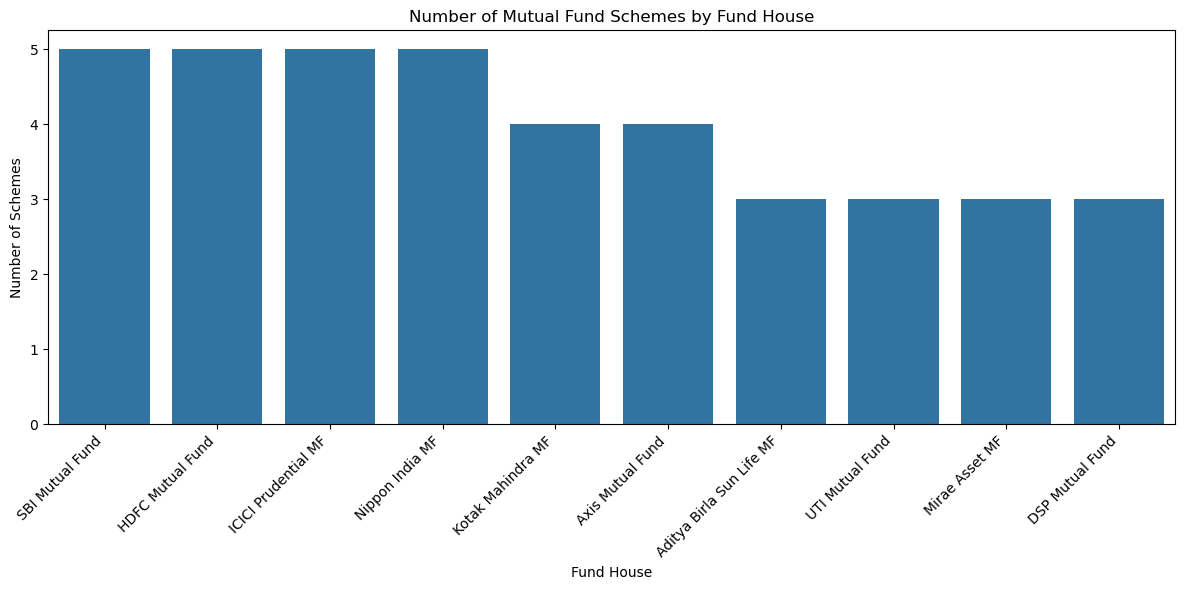

In [9]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=fund_house_counts,
    x="fund_house",
    y="fund_count"
)

plt.title("Number of Mutual Fund Schemes by Fund House")
plt.xlabel("Fund House")
plt.ylabel("Number of Schemes")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [10]:
category_counts = (
    fund_master_df["category"]
    .value_counts()
    .reset_index()
)

category_counts.columns = [
    "category",
    "fund_count"
]

display(category_counts)

,category,fund_count
0,Equity,34
1,Debt,6


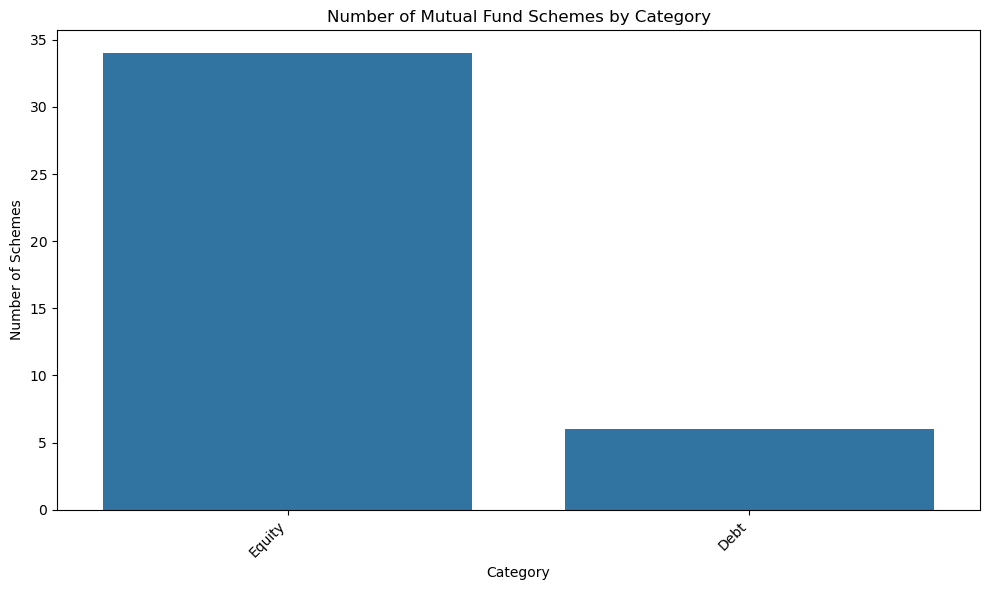

In [11]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_counts,
    x="category",
    y="fund_count"
)

plt.title("Number of Mutual Fund Schemes by Category")
plt.xlabel("Category")
plt.ylabel("Number of Schemes")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [12]:
risk_counts = (
    fund_master_df["risk_category"]
    .value_counts()
    .reset_index()
)

risk_counts.columns = [
    "risk_category",
    "fund_count"
]

display(risk_counts)

,risk_category,fund_count
0,Moderate,16
1,High,8
2,Very High,6
3,Low,6
4,Moderately High,4


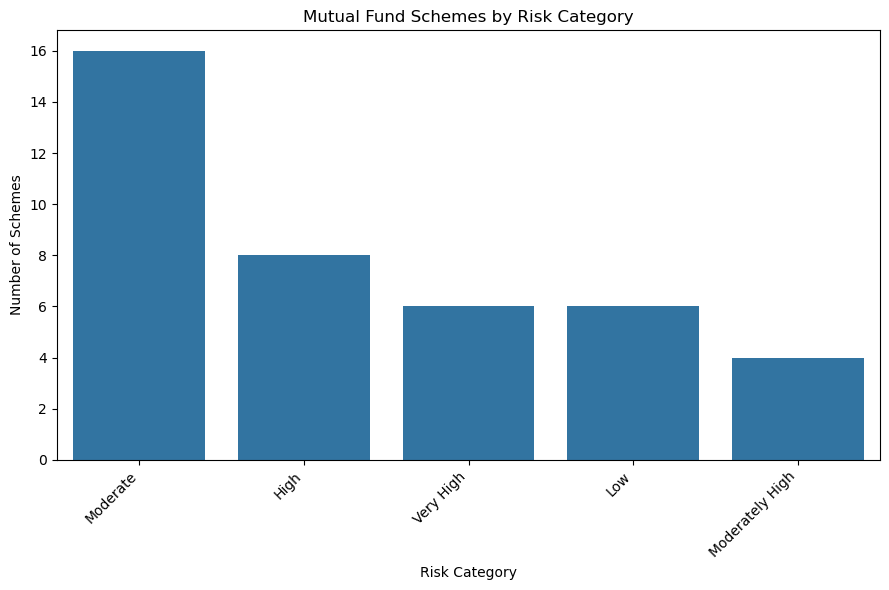

In [13]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=risk_counts,
    x="risk_category",
    y="fund_count"
)

plt.title("Mutual Fund Schemes by Risk Category")
plt.xlabel("Risk Category")
plt.ylabel("Number of Schemes")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [14]:
performance_numeric = performance_df.select_dtypes(
    include=["int64", "float64"]
)

performance_summary = performance_numeric.describe().T

display(performance_summary)

,count,mean,std,min,25%,50%,75%,max
amfi_code,40.0,120247.00000,14534.998667,100016.00,118632.7500,119551.500,120842.2500,149324.00
return_1yr_pct,40.0,14.37600,4.883023,4.26,11.7350,14.620,16.3925,24.93
return_3yr_pct,40.0,14.08900,4.617253,5.14,12.0350,14.205,15.8825,23.39
return_5yr_pct,40.0,14.51675,4.454021,5.43,12.3400,14.185,17.5850,23.80
benchmark_3yr_pct,40.0,12.83550,4.740972,3.96,10.6900,13.090,14.7750,22.16
alpha,40.0,1.25350,0.447412,0.51,0.8875,1.205,1.7000,1.98
beta,40.0,0.87325,0.224846,0.22,0.8900,0.960,1.0000,1.04
sharpe_ratio,40.0,1.36175,1.475805,0.80,0.8650,0.925,0.9850,7.68
sortino_ratio,40.0,2.08250,2.203144,1.03,1.2700,1.445,1.6375,10.37
std_dev_ann_pct,40.0,14.96250,6.669282,0.50,14.0000,14.000,19.0000,25.00


In [15]:
key_metrics = [
    "return_1yr_pct",
    "return_3yr_pct",
    "return_5yr_pct",
    "alpha",
    "beta",
    "sharpe_ratio",
    "sortino_ratio",
    "std_dev_ann_pct",
    "max_drawdown_pct",
    "expense_ratio_pct",
    "aum_crore"
]

performance_df[key_metrics].describe().T

,count,mean,std,min,25%,50%,75%,max
return_1yr_pct,40.0,14.37600,4.883023,4.26,11.7350,14.620,16.3925,24.93
return_3yr_pct,40.0,14.08900,4.617253,5.14,12.0350,14.205,15.8825,23.39
return_5yr_pct,40.0,14.51675,4.454021,5.43,12.3400,14.185,17.5850,23.80
alpha,40.0,1.25350,0.447412,0.51,0.8875,1.205,1.7000,1.98
beta,40.0,0.87325,0.224846,0.22,0.8900,0.960,1.0000,1.04
sharpe_ratio,40.0,1.36175,1.475805,0.80,0.8650,0.925,0.9850,7.68
sortino_ratio,40.0,2.08250,2.203144,1.03,1.2700,1.445,1.6375,10.37
std_dev_ann_pct,40.0,14.96250,6.669282,0.50,14.0000,14.000,19.0000,25.00
max_drawdown_pct,40.0,-19.20025,8.819164,-33.50,-25.0625,-20.600,-14.2550,-2.23
expense_ratio_pct,40.0,1.23700,0.386584,0.55,0.7875,1.425,1.5400,1.64


In [16]:
q1 = performance_df["return_3yr_pct"].quantile(0.25)
q3 = performance_df["return_3yr_pct"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

return_outliers = performance_df[
    (performance_df["return_3yr_pct"] < lower_bound) |
    (performance_df["return_3yr_pct"] > upper_bound)
]

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("\nPotential 3-year return outliers:")
display(
    return_outliers[
        [
            "amfi_code",
            "return_3yr_pct",
            "scheme_name"
        ]
    ]
)

Q1: 12.035
Q3: 15.8825
IQR: 3.8475
Lower bound: 6.26375
Upper bound: 21.653750000000002

Potential 3-year return outliers:


,amfi_code,return_3yr_pct,scheme_name
2,119598,23.39,SBI Small Cap Fund - Regular Plan - Growth
3,119599,23.14,SBI Small Cap Fund - Direct Plan - Growth
4,119120,6.07,SBI Magnum Gilt Fund - Regular Plan - Growth
19,118636,5.31,Nippon India Gilt Securities Fund - Regular - ...
23,120844,6.18,Kotak Liquid Fund - Regular - Growth
29,101207,22.38,ABSL Small Cap Fund - Regular - Growth
30,101208,5.14,ABSL Liquid Fund - Regular - Growth


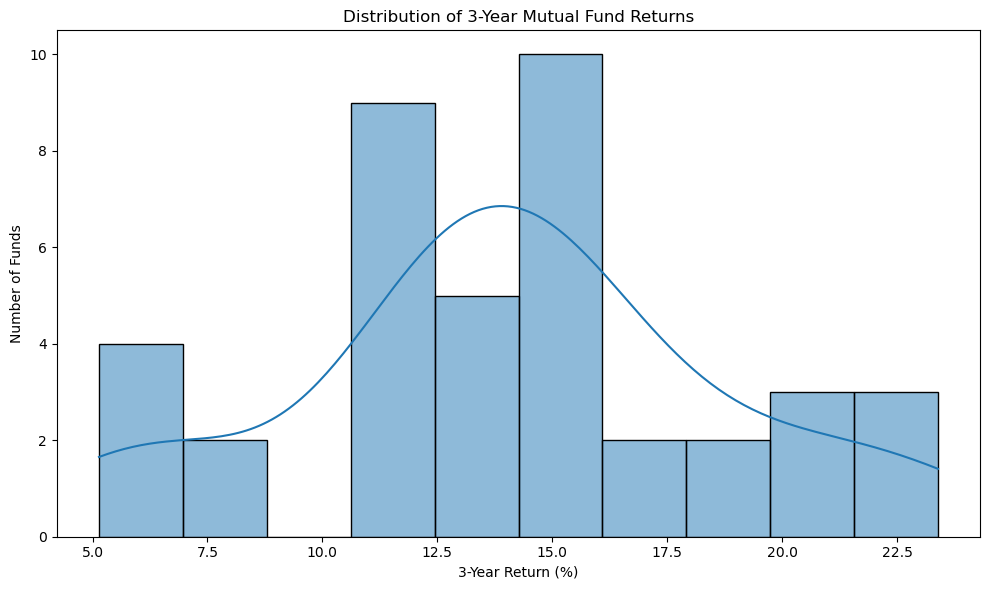

In [17]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=performance_df,
    x="return_3yr_pct",
    bins=10,
    kde=True
)

plt.title("Distribution of 3-Year Mutual Fund Returns")
plt.xlabel("3-Year Return (%)")
plt.ylabel("Number of Funds")

plt.tight_layout()
plt.show()

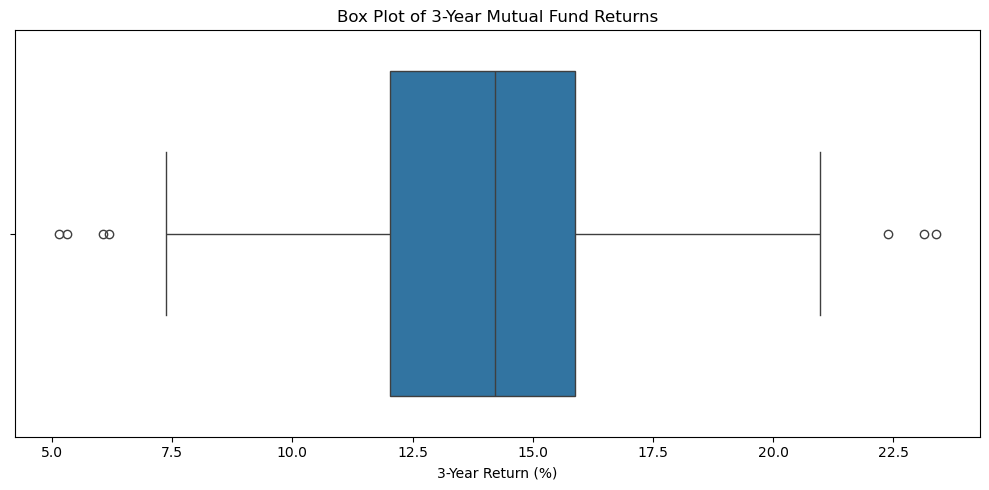

In [18]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=performance_df["return_3yr_pct"]
)

plt.title("Box Plot of 3-Year Mutual Fund Returns")
plt.xlabel("3-Year Return (%)")

plt.tight_layout()
plt.show()

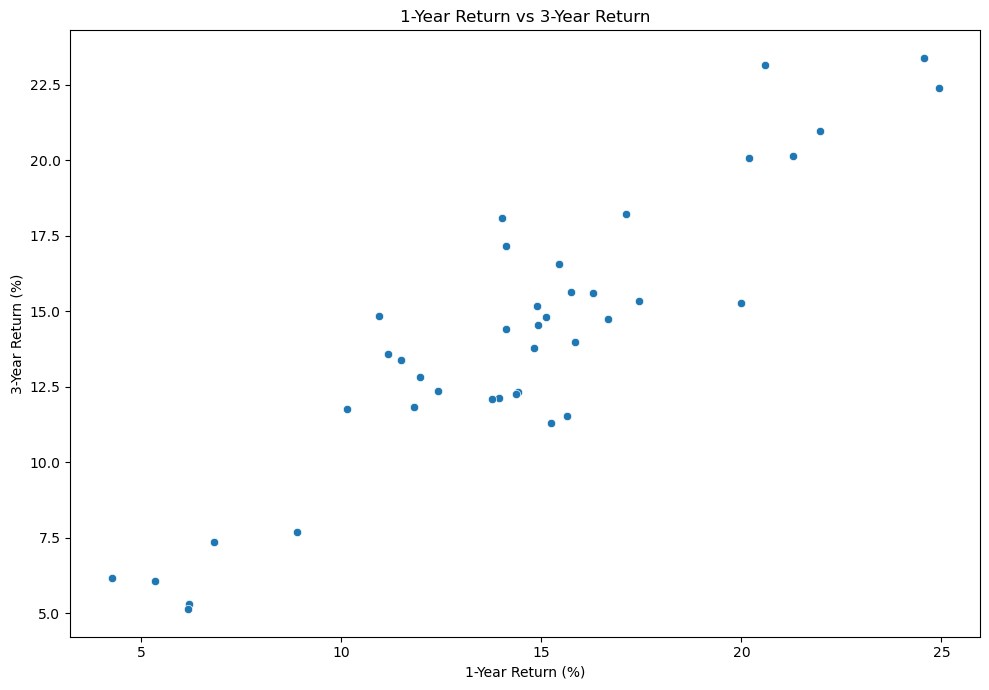

In [19]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=performance_df,
    x="return_1yr_pct",
    y="return_3yr_pct"
)

plt.title("1-Year Return vs 3-Year Return")
plt.xlabel("1-Year Return (%)")
plt.ylabel("3-Year Return (%)")

plt.tight_layout()
plt.show()

In [20]:
aum_by_house = (
    aum_df.groupby("fund_house")["aum_crore"]
    .sum()
    .sort_values(ascending=False)
)

print(aum_by_house)

fund_house
SBI Mutual Fund             8491000
ICICI Prudential MF         6293000
HDFC Mutual Fund            5732000
Nippon India MF             3909000
Kotak Mahindra MF           3502000
Aditya Birla Sun Life MF    3077000
UTI Mutual Fund             2681000
Axis Mutual Fund            2521000
Mirae Asset MF              1561000
DSP Mutual Fund             1409000
Name: aum_crore, dtype: int64


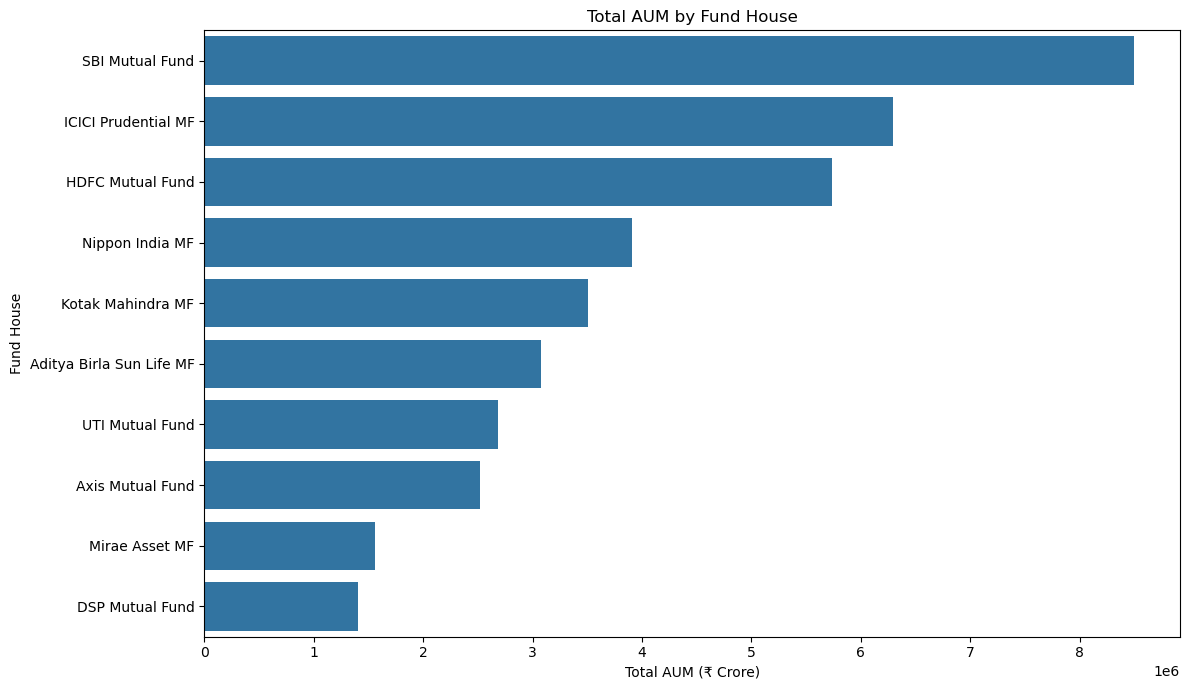

In [21]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=aum_by_house.values,
    y=aum_by_house.index
)

plt.title("Total AUM by Fund House")
plt.xlabel("Total AUM (₹ Crore)")
plt.ylabel("Fund House")

plt.tight_layout()
plt.show()

In [22]:
monthly_aum = (
    aum_df.groupby("date")["aum_crore"]
    .sum()
    .sort_index()
)

print(monthly_aum)

date
2022-03-31    3018000
2022-09-30    3090000
2023-03-31    3235000
2023-09-30    3742000
2024-03-31    4375000
2024-09-30    4727000
2024-12-31    5268000
2025-03-31    5447000
2025-12-31    6274000
Name: aum_crore, dtype: int64


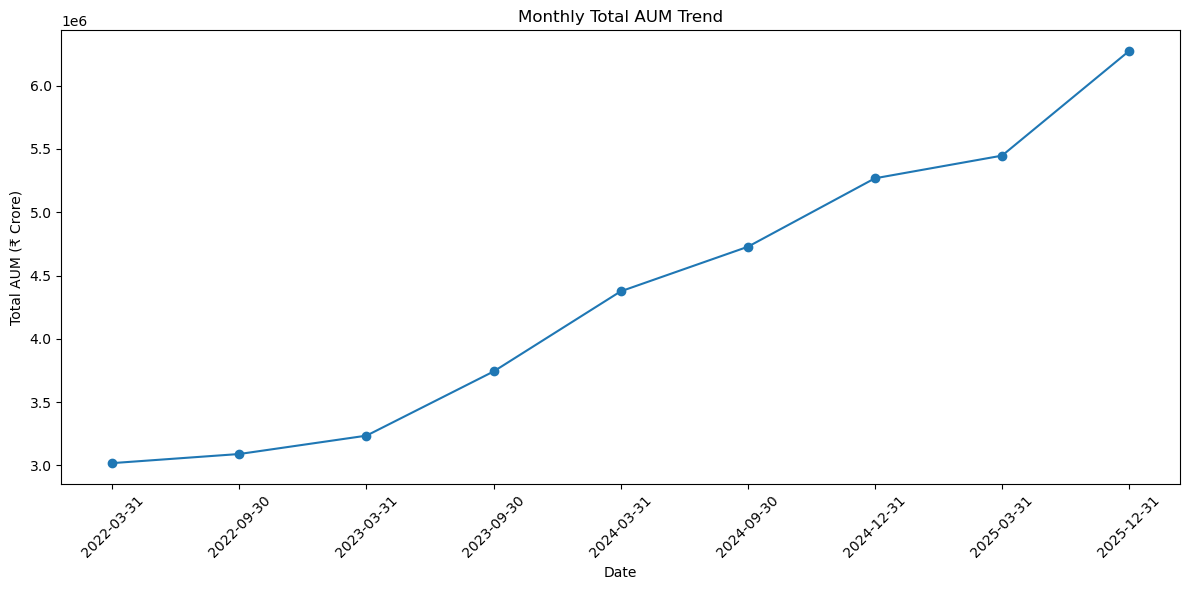

In [23]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_aum.index,
    monthly_aum.values,
    marker="o"
)

plt.title("Monthly Total AUM Trend")
plt.xlabel("Date")
plt.ylabel("Total AUM (₹ Crore)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [26]:
print(sip_df.columns.tolist())

['month', 'sip_inflow_crore', 'active_sip_accounts_crore', 'new_sip_accounts_lakh', 'sip_aum_lakh_crore', 'yoy_growth_pct']


In [27]:
print(sip_df.head())

     month  sip_inflow_crore  active_sip_accounts_crore  \
0  2022-01             11517                       4.91   
1  2022-02             11438                       4.93   
2  2022-03             12328                       5.09   
3  2022-04             11863                       5.48   
4  2022-05             12286                       5.55   

   new_sip_accounts_lakh  sip_aum_lakh_crore  yoy_growth_pct  
0                   9.10                4.80             NaN  
1                   8.20                4.85             NaN  
2                  10.50                5.01             NaN  
3                   9.52                5.12             NaN  
4                   8.10                5.15             NaN  


In [28]:
sip_df["month"] = pd.to_datetime(sip_df["month"])

monthly_sip = (
    sip_df.groupby("month")["sip_inflow_crore"]
    .sum()
    .sort_index()
)

print(monthly_sip)

month
2022-01-01    11517
2022-02-01    11438
2022-03-01    12328
2022-04-01    11863
2022-05-01    12286
2022-06-01    12276
2022-07-01    12140
2022-08-01    12694
2022-09-01    12976
2022-10-01    13040
2022-11-01    13306
2022-12-01    13573
2023-01-01    13856
2023-02-01    13687
2023-03-01    14276
2023-04-01    14749
2023-05-01    14749
2023-06-01    14734
2023-07-01    15245
2023-08-01    15814
2023-09-01    16042
2023-10-01    16928
2023-11-01    17073
2023-12-01    17610
2024-01-01    18838
2024-02-01    19187
2024-03-01    20371
2024-04-01    20371
2024-05-01    21262
2024-06-01    21262
2024-07-01    23332
2024-08-01    23547
2024-09-01    24509
2024-10-01    25323
2024-11-01    25320
2024-12-01    26459
2025-01-01    26400
2025-02-01    25999
2025-03-01    25926
2025-04-01    26632
2025-05-01    26688
2025-06-01    27274
2025-07-01    28464
2025-08-01    28265
2025-09-01    29361
2025-10-01    29529
2025-11-01    30200
2025-12-01    31002
Name: sip_inflow_crore, dtype: int

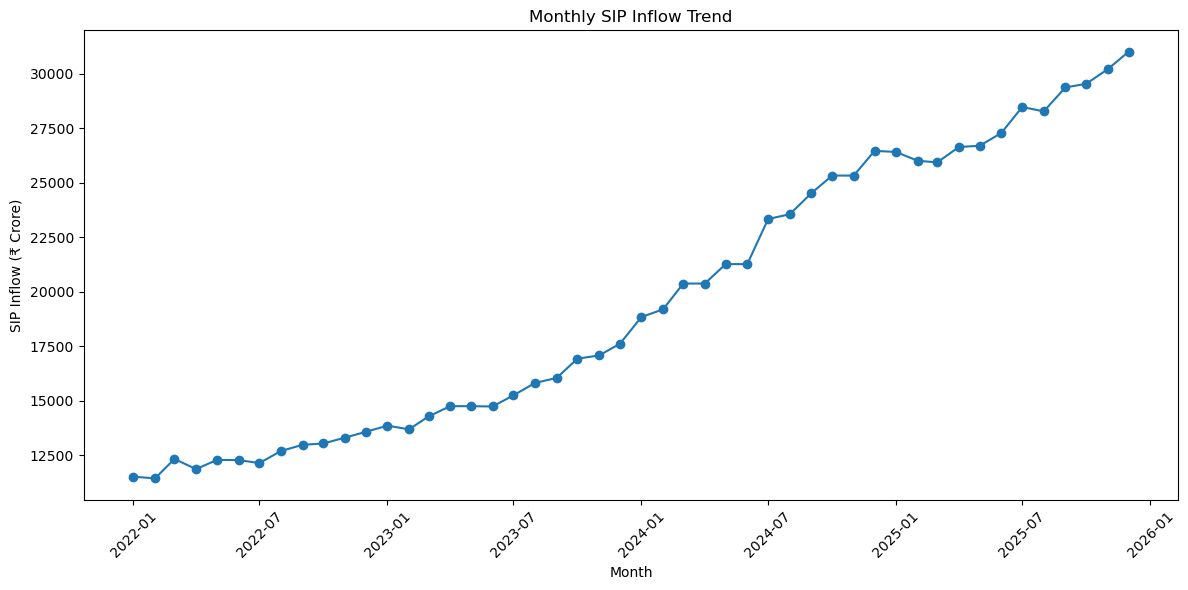

In [29]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sip.index,
    monthly_sip.values,
    marker="o"
)

plt.title("Monthly SIP Inflow Trend")
plt.xlabel("Month")
plt.ylabel("SIP Inflow (₹ Crore)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [30]:
sip_yoy = sip_df.dropna(subset=["yoy_growth_pct"]).copy()

print(sip_yoy["yoy_growth_pct"].describe())

count    36.000000
mean     31.456944
std      11.768190
min      15.800000
25%      20.245000
50%      28.295000
75%      40.807500
max      53.050000
Name: yoy_growth_pct, dtype: float64


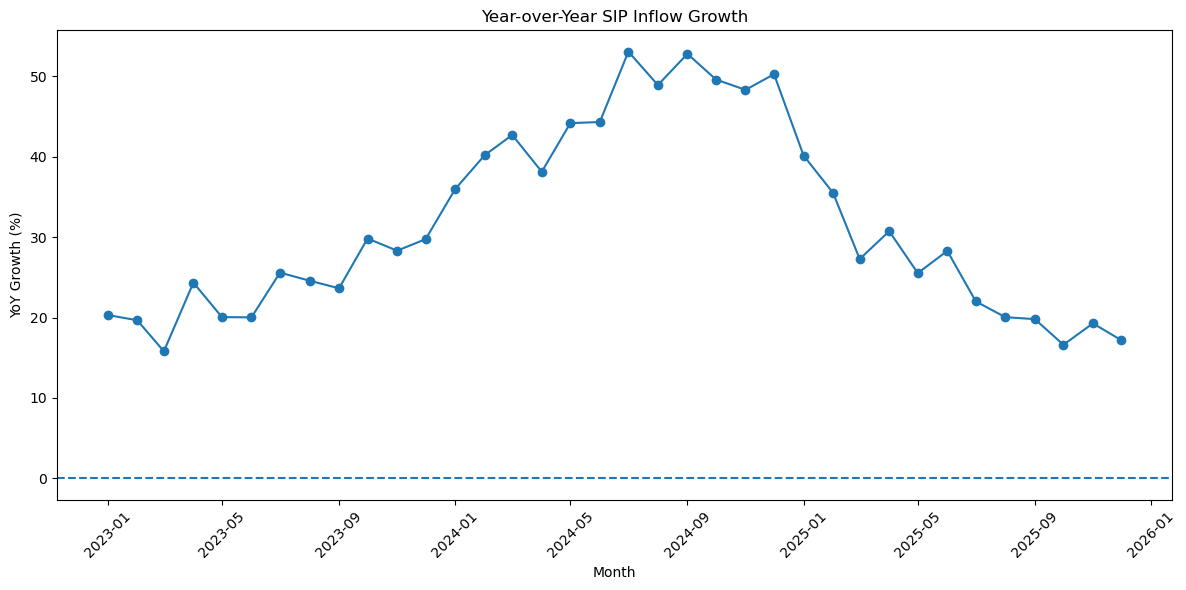

In [31]:
plt.figure(figsize=(12, 6))

plt.plot(
    sip_yoy["month"],
    sip_yoy["yoy_growth_pct"],
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.title("Year-over-Year SIP Inflow Growth")
plt.xlabel("Month")
plt.ylabel("YoY Growth (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [32]:
print(category_inflows_df.columns.tolist())
print(category_inflows_df.head())

['month', 'category', 'net_inflow_crore']
     month         category  net_inflow_crore
0  2024-04        Large Cap            2413.0
1  2024-04          Mid Cap            3897.0
2  2024-04        Small Cap            3533.0
3  2024-04        Flexi Cap            4947.0
4  2024-04  Large & Mid Cap            4214.0


In [33]:
category_sip = (
    category_inflows_df.groupby("category")["net_inflow_crore"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sip)

category
Liquid               451275.0
Sectoral/Thematic    103829.0
Flexi Cap             63989.0
Large & Mid Cap       57752.0
Short Duration        55530.0
Mid Cap               55312.0
Small Cap             46596.0
Hybrid                38868.0
Large Cap             25633.0
Value/Contra          16980.0
Gilt                  10395.0
ELSS                   6080.0
Name: net_inflow_crore, dtype: float64


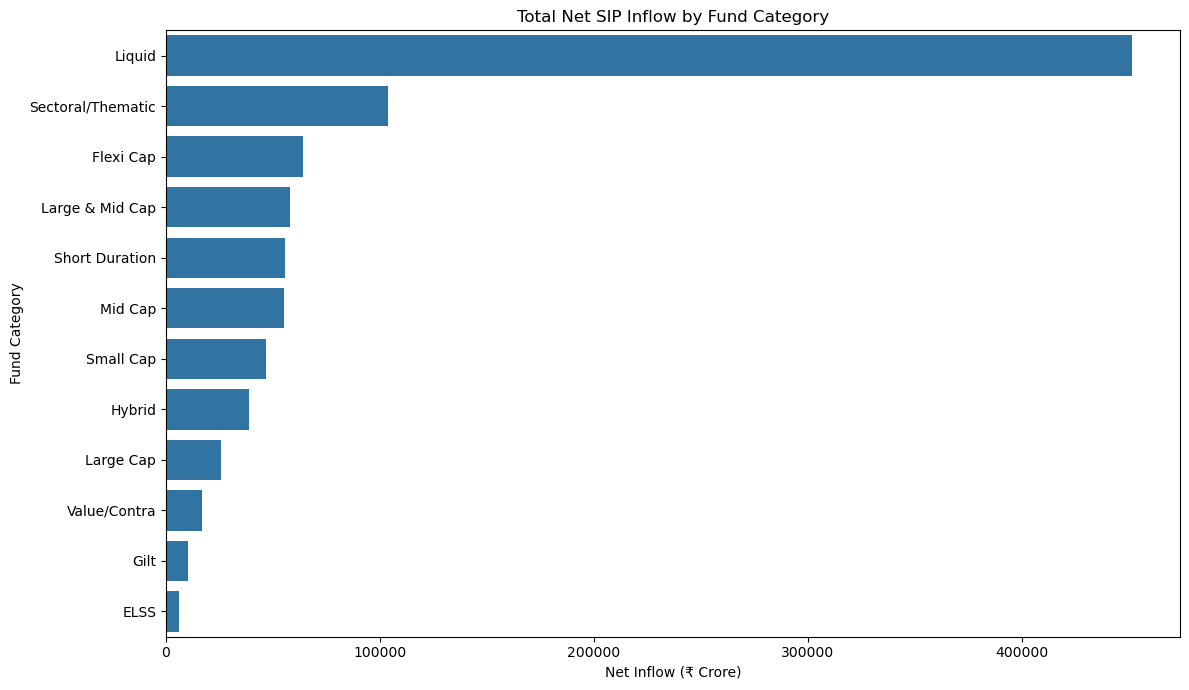

In [34]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=category_sip.values,
    y=category_sip.index
)

plt.title("Total Net SIP Inflow by Fund Category")
plt.xlabel("Net Inflow (₹ Crore)")
plt.ylabel("Fund Category")

plt.tight_layout()
plt.show()

In [35]:
transaction_type_counts = (
    transactions_df["transaction_type"]
    .value_counts()
)

print(transaction_type_counts)

transaction_type
SIP           19716
Lumpsum        8095
Redemption     4967
Name: count, dtype: int64


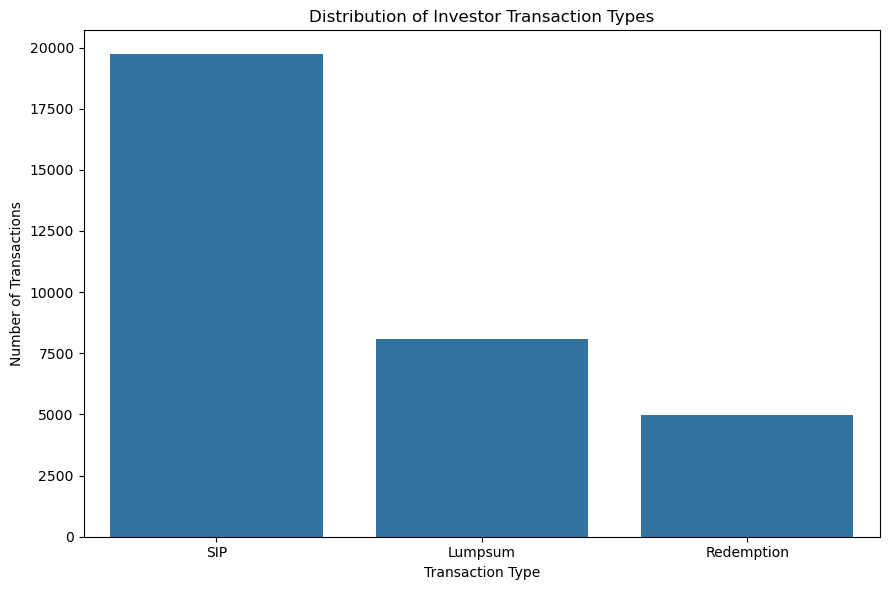

In [36]:
plt.figure(figsize=(9, 6))

sns.barplot(
    x=transaction_type_counts.index,
    y=transaction_type_counts.values
)

plt.title("Distribution of Investor Transaction Types")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

In [37]:
transaction_amount = (
    transactions_df.groupby("transaction_type")["amount_inr"]
    .agg(["sum", "mean", "count"])
    .sort_values("sum", ascending=False)
)

print(transaction_amount)

                         sum           mean  count
transaction_type                                  
Lumpsum           2059821448  254456.015812   8095
Redemption        1244525491  250558.786189   4967
SIP                217233491   11018.132025  19716


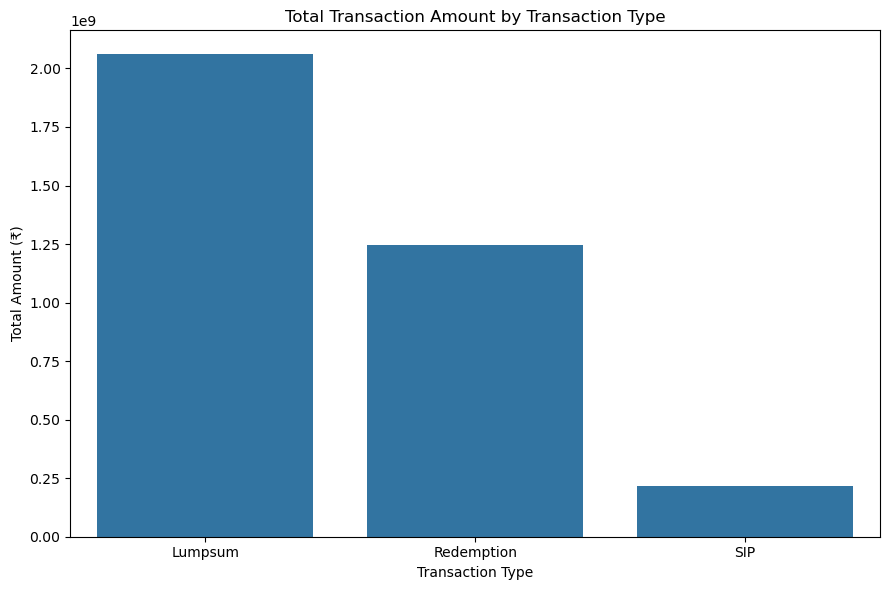

In [38]:
plt.figure(figsize=(9, 6))

sns.barplot(
    x=transaction_amount.index,
    y=transaction_amount["sum"]
)

plt.title("Total Transaction Amount by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Total Amount (₹)")

plt.tight_layout()
plt.show()

In [39]:
state_transactions = (
    transactions_df["state"]
    .value_counts()
)

print(state_transactions)

state
Punjab            2965
Madhya Pradesh    2931
Tamil Nadu        2806
Gujarat           2780
West Bengal       2748
Haryana           2736
Telangana         2718
Uttar Pradesh     2695
Delhi             2677
Karnataka         2621
Rajasthan         2577
Maharashtra       2524
Name: count, dtype: int64


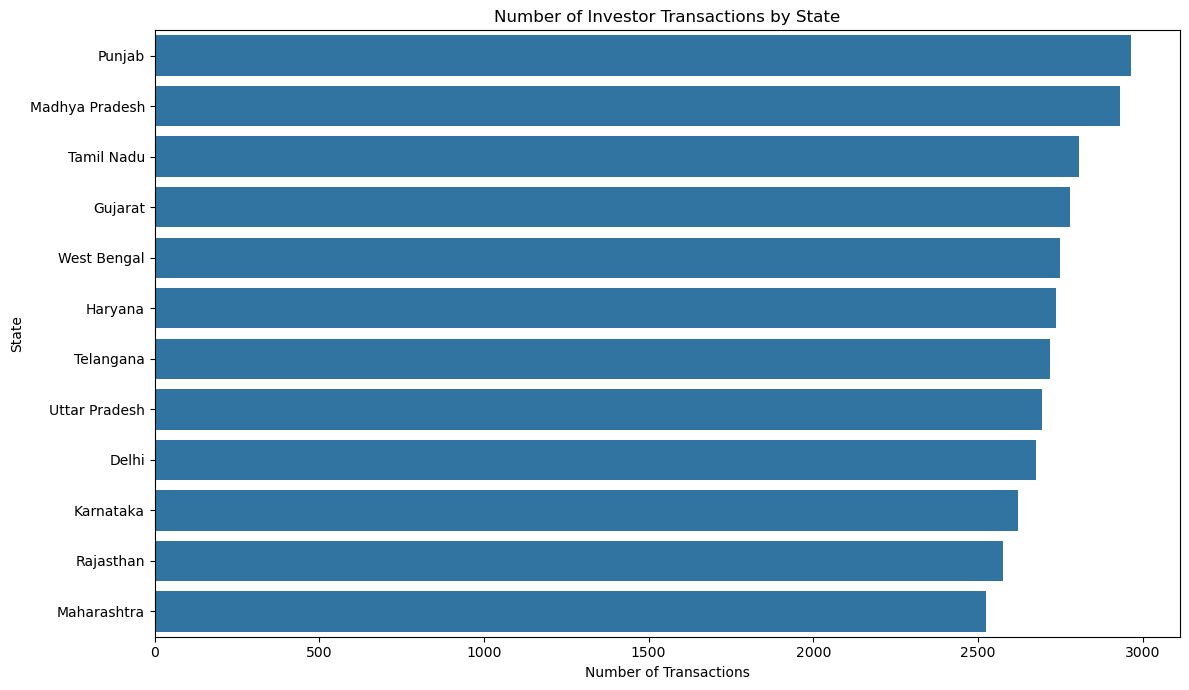

In [40]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=state_transactions.values,
    y=state_transactions.index
)

plt.title("Number of Investor Transactions by State")
plt.xlabel("Number of Transactions")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [41]:
state_amount = (
    transactions_df.groupby("state")["amount_inr"]
    .sum()
    .sort_values(ascending=False)
)

print(state_amount)

state
Punjab            315780459
Tamil Nadu        315177237
Madhya Pradesh    308312493
Rajasthan         298645822
Gujarat           298358940
West Bengal       297182514
Telangana         290219284
Delhi             289633404
Uttar Pradesh     285368873
Haryana           279634354
Karnataka         273753570
Maharashtra       269513480
Name: amount_inr, dtype: int64


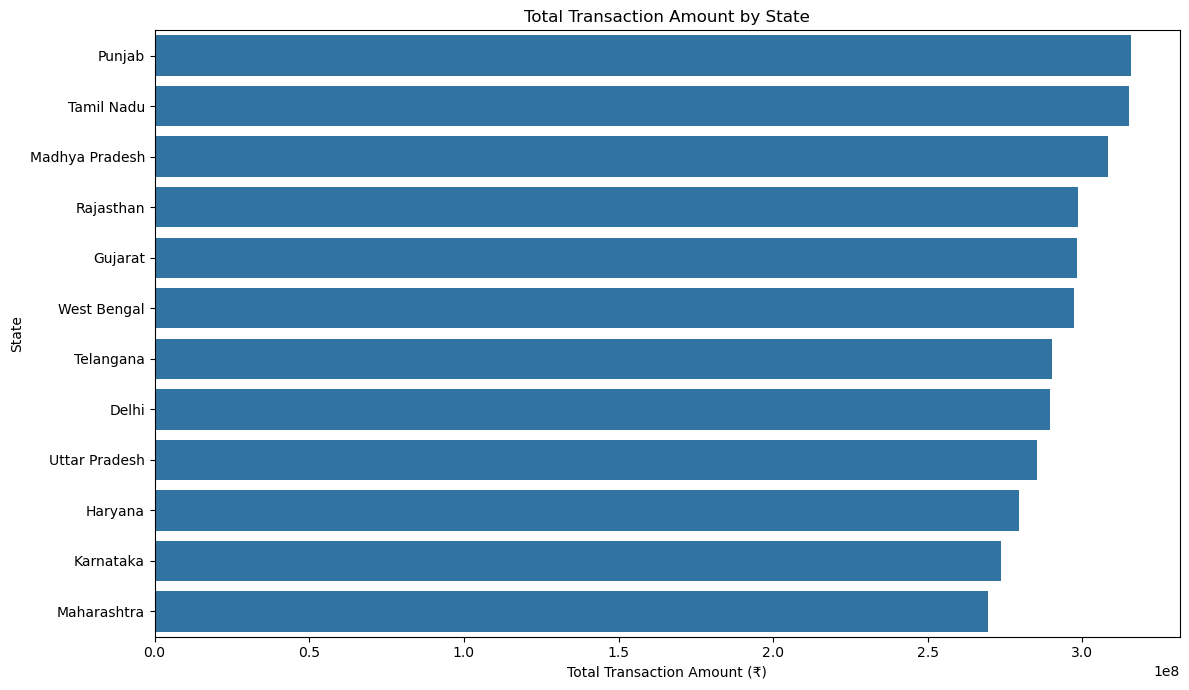

In [42]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=state_amount.values,
    y=state_amount.index
)

plt.title("Total Transaction Amount by State")
plt.xlabel("Total Transaction Amount (₹)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [43]:
city_tier_counts = (
    transactions_df["city_tier"]
    .value_counts()
)

print(city_tier_counts)

city_tier
T30    21719
B30    11059
Name: count, dtype: int64


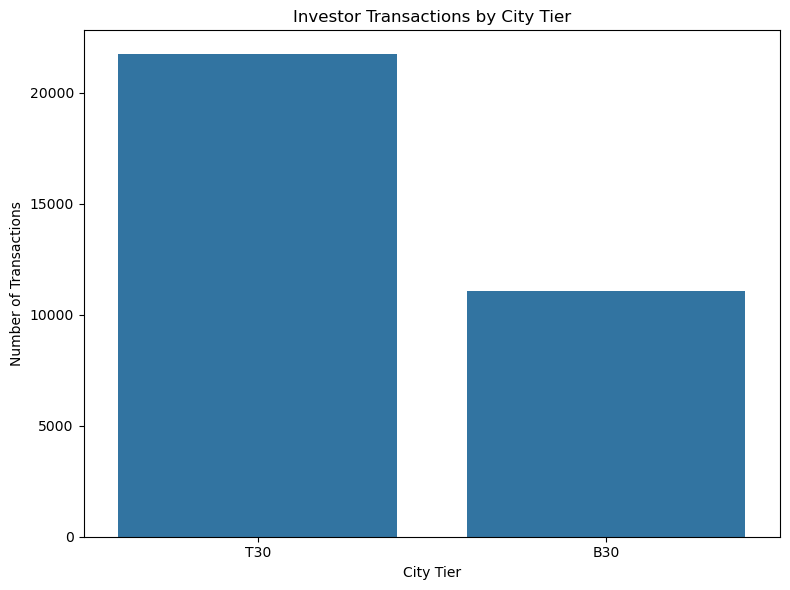

In [44]:
plt.figure(figsize=(8, 6))

sns.barplot(
    x=city_tier_counts.index,
    y=city_tier_counts.values
)

plt.title("Investor Transactions by City Tier")
plt.xlabel("City Tier")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

task 1 

In [45]:
print(nav_df.shape)
print(nav_df.head())
print(nav_df["date"].min())
print(nav_df["date"].max())
print(nav_df["amfi_code"].nunique())

(46000, 3)
   amfi_code        date       nav
0     100016  2022-01-03  520.4608
1     100016  2022-01-04  515.0971
2     100016  2022-01-05  521.7239
3     100016  2022-01-06  515.7880
4     100016  2022-01-07  515.1639
2022-01-03
2026-05-29
40


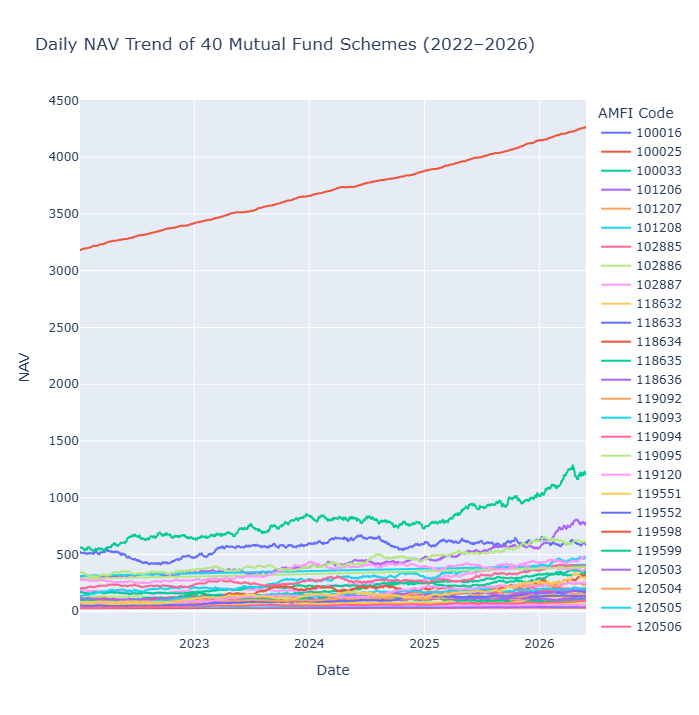

In [47]:
import plotly.express as px

fig = px.line(
    nav_df,
    x="date",
    y="nav",
    color="amfi_code",
    title="Daily NAV Trend of 40 Mutual Fund Schemes (2022–2026)",
    labels={
        "date": "Date",
        "nav": "NAV",
        "amfi_code": "AMFI Code"
    }
)

fig.update_layout(
    width=1200,
    height=700,
    hovermode="x unified"
)

fig.show()

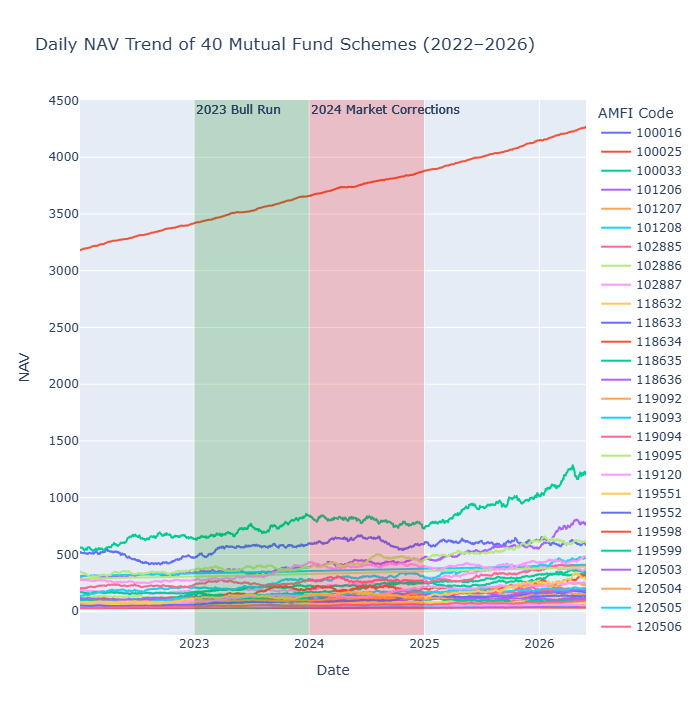

In [50]:
fig.add_vrect(
    x0="2023-01-01",
    x1="2023-12-31",
    fillcolor="green",
    opacity=0.10,
    line_width=0,
    annotation_text="2023 Bull Run",
    annotation_position="top left"
)

fig.add_vrect(
    x0="2024-01-01",
    x1="2024-12-31",
    fillcolor="red",
    opacity=0.10,
    line_width=0,
    annotation_text="2024 Market Corrections",
    annotation_position="top left"
)

fig.show()

task 2

In [51]:
aum_df["date"] = pd.to_datetime(aum_df["date"])

aum_df["year"] = aum_df["date"].dt.year

aum_yearly = (
    aum_df[
        (aum_df["year"] >= 2022) &
        (aum_df["year"] <= 2025)
    ]
    .groupby(["year", "fund_house"])["aum_lakh_crore"]
    .sum()
    .reset_index()
)

print(aum_yearly.head())

   year                fund_house  aum_lakh_crore
0  2022  Aditya Birla Sun Life MF            5.63
1  2022          Axis Mutual Fund            4.90
2  2022           DSP Mutual Fund            2.22
3  2022          HDFC Mutual Fund            8.80
4  2022       ICICI Prudential MF            9.53


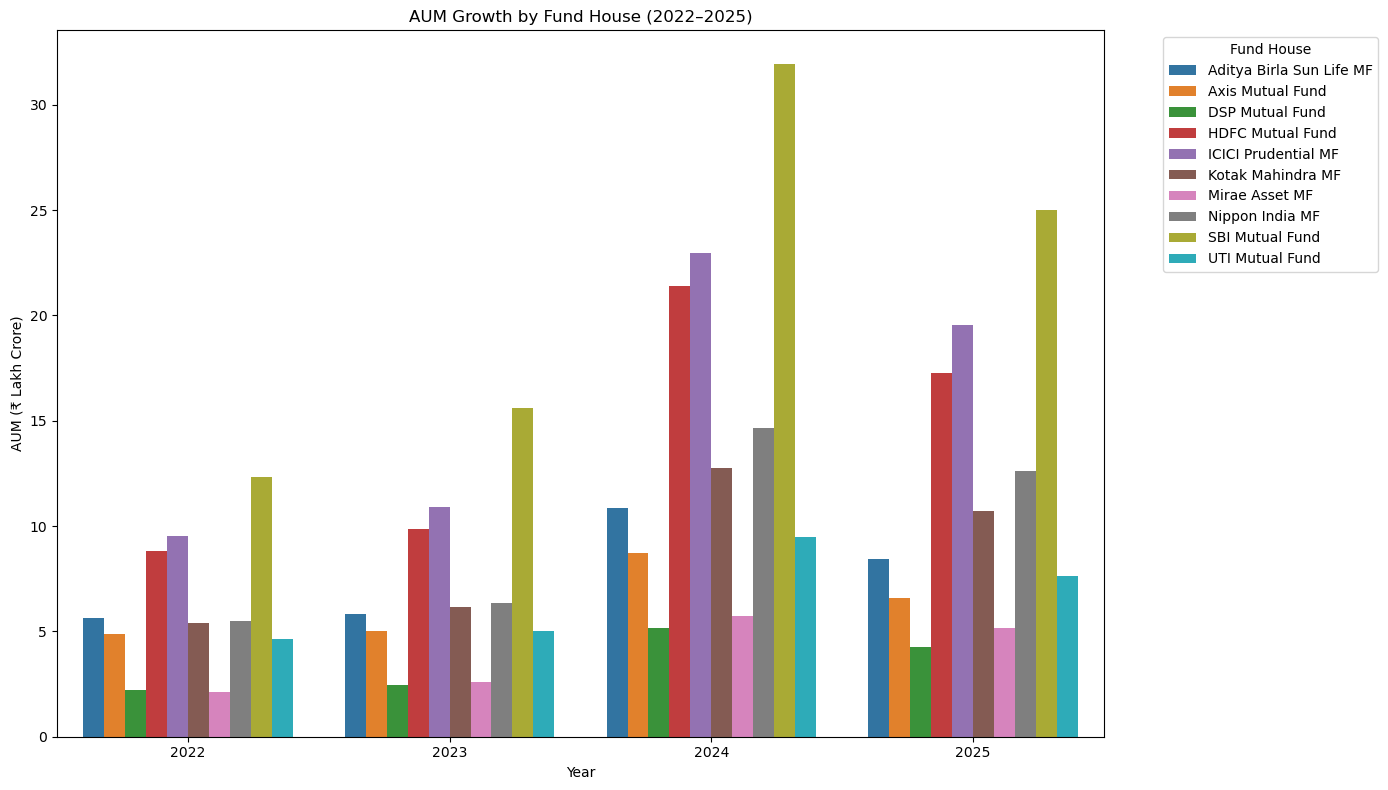

In [52]:
plt.figure(figsize=(14, 8))

sns.barplot(
    data=aum_yearly,
    x="year",
    y="aum_lakh_crore",
    hue="fund_house"
)

plt.title("AUM Growth by Fund House (2022–2025)")
plt.xlabel("Year")
plt.ylabel("AUM (₹ Lakh Crore)")

plt.legend(
    title="Fund House",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [53]:
print(
    aum_yearly[
        aum_yearly["fund_house"].str.contains("SBI", case=False, na=False)
    ]
)

    year       fund_house  aum_lakh_crore
8   2022  SBI Mutual Fund           12.35
18  2023  SBI Mutual Fund           15.62
28  2024  SBI Mutual Fund           31.94
38  2025  SBI Mutual Fund           25.00


task 3 

In [94]:
sip_df["month"] = pd.to_datetime(sip_df["month"])

sip_trend = (
    sip_df[
        (sip_df["month"] >= "2022-01-01") &
        (sip_df["month"] <= "2025-12-31")
    ]
    .sort_values("month")
    .copy()
)

print(sip_trend.shape)
print(sip_trend[["month", "sip_inflow_crore"]].head())
print(sip_trend[["month", "sip_inflow_crore"]].tail())

(48, 6)
       month  sip_inflow_crore
0 2022-01-01             11517
1 2022-02-01             11438
2 2022-03-01             12328
3 2022-04-01             11863
4 2022-05-01             12286
        month  sip_inflow_crore
43 2025-08-01             28265
44 2025-09-01             29361
45 2025-10-01             29529
46 2025-11-01             30200
47 2025-12-01             31002


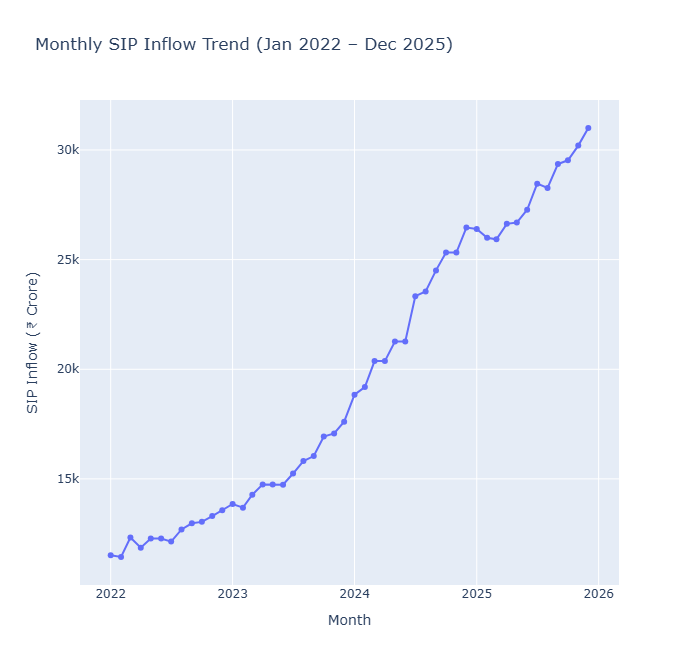

In [56]:
dec_2025 = sip_trend[sip_trend["month"] == "2025-12-01"]

print(dec_2025[["month", "sip_inflow_crore"]])

        month  sip_inflow_crore
47 2025-12-01             31002


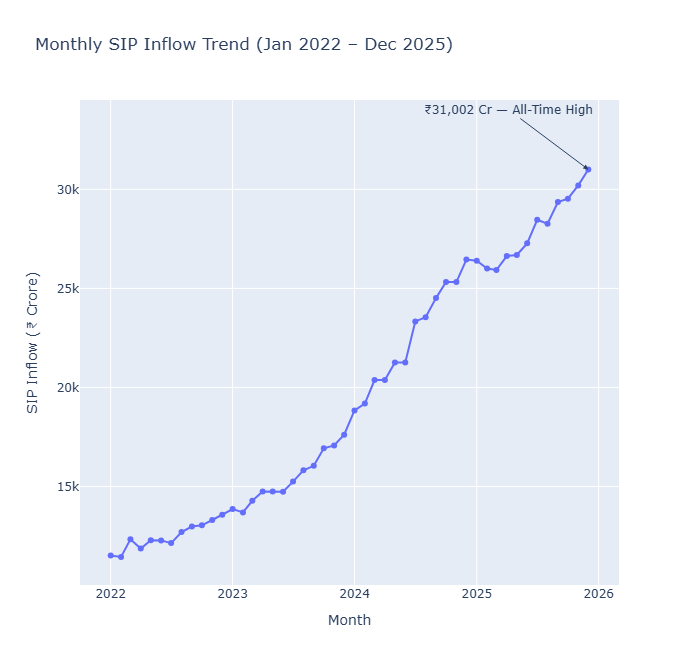

In [57]:
fig.add_annotation(
    x="2025-12-01",
    y=31002,
    text="₹31,002 Cr — All-Time High",
    showarrow=True,
    arrowhead=2,
    ax=-80,
    ay=-60
)

fig.show()

task 4

In [71]:
# Convert month to datetime
category_inflows_df["month"] = pd.to_datetime(category_inflows_df["month"])

# Keep the required period
category_heatmap = category_inflows_df[
    (category_inflows_df["month"] >= "2022-01-01") &
    (category_inflows_df["month"] <= "2025-12-31")
].copy()

print(category_heatmap.shape)
print(category_heatmap.head())

(144, 3)
       month         category  net_inflow_crore
0 2024-04-01        Large Cap            2413.0
1 2024-04-01          Mid Cap            3897.0
2 2024-04-01        Small Cap            3533.0
3 2024-04-01        Flexi Cap            4947.0
4 2024-04-01  Large & Mid Cap            4214.0


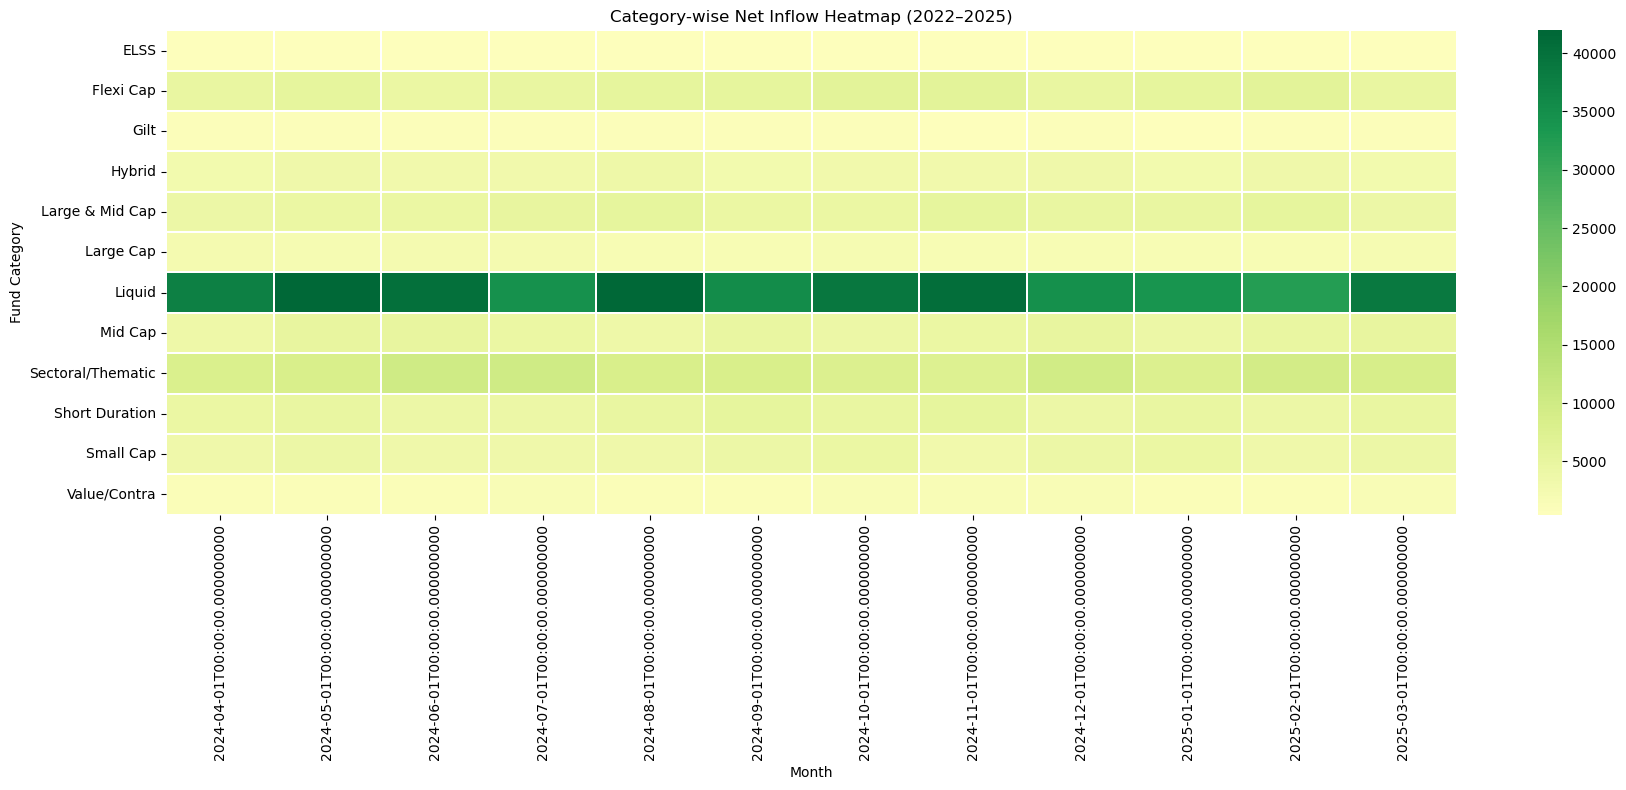

In [72]:
import seaborn as sns
import matplotlib.pyplot as plt

# Convert data into heatmap format
heatmap_data = category_heatmap.pivot_table(
    index="category",
    columns="month",
    values="net_inflow_crore",
    aggfunc="sum"
)

plt.figure(figsize=(18, 8))

sns.heatmap(
    heatmap_data,
    cmap="RdYlGn",
    center=0,
    linewidths=0.3
)

plt.title("Category-wise Net Inflow Heatmap (2022–2025)")
plt.xlabel("Month")
plt.ylabel("Fund Category")

plt.tight_layout()
plt.show()

task 5 

In [74]:
print("Shape:", transactions_df.shape)
print("\nAge groups:")
print(transactions_df["age_group"].value_counts())

print("\nGender:")
print(transactions_df["gender"].value_counts())

print("\nTransaction types:")
print(transactions_df["transaction_type"].value_counts())

Shape: (32778, 13)

Age groups:
age_group
26-35    13463
36-45     8146
18-25     4916
46-55     3779
56+       2474
Name: count, dtype: int64

Gender:
gender
Male      21809
Female    10969
Name: count, dtype: int64

Transaction types:
transaction_type
SIP           19716
Lumpsum        8095
Redemption     4967
Name: count, dtype: int64


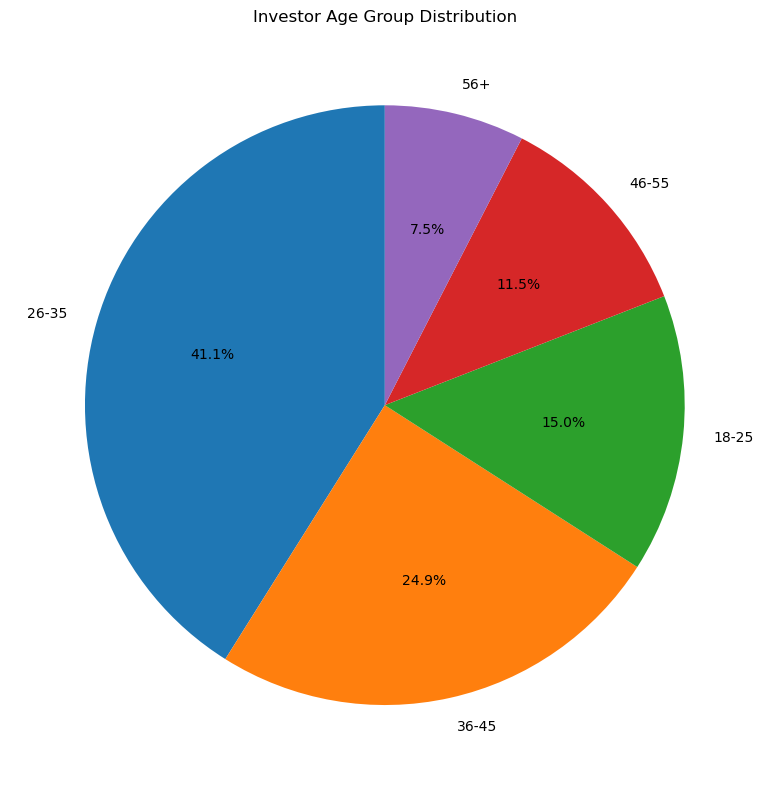

In [75]:
import matplotlib.pyplot as plt

age_counts = transactions_df["age_group"].value_counts()

fig, ax = plt.subplots(figsize=(8, 8))

ax.pie(
    age_counts.values,
    labels=age_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

ax.set_title("Investor Age Group Distribution")

plt.tight_layout()

fig.savefig(
    "../Reports/investor_age_group_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

SIP transactions: 19716


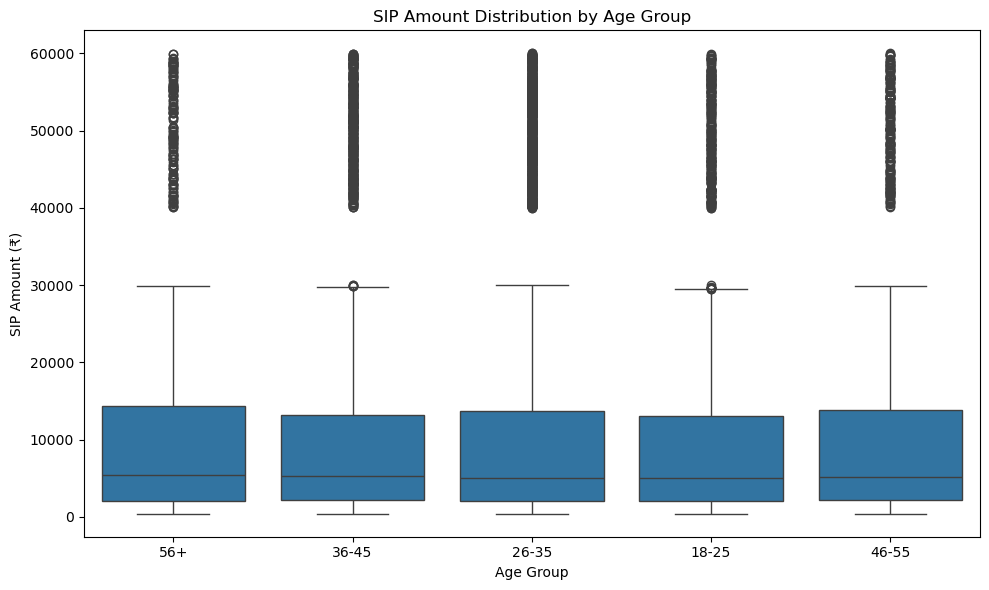

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

sip_transactions = transactions_df[
    transactions_df["transaction_type"] == "SIP"
].copy()

print("SIP transactions:", len(sip_transactions))

fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=sip_transactions,
    x="age_group",
    y="amount_inr",
    ax=ax
)

ax.set_title("SIP Amount Distribution by Age Group")
ax.set_xlabel("Age Group")
ax.set_ylabel("SIP Amount (₹)")

plt.tight_layout()

fig.savefig(
    "../Reports/sip_amount_by_age_group.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

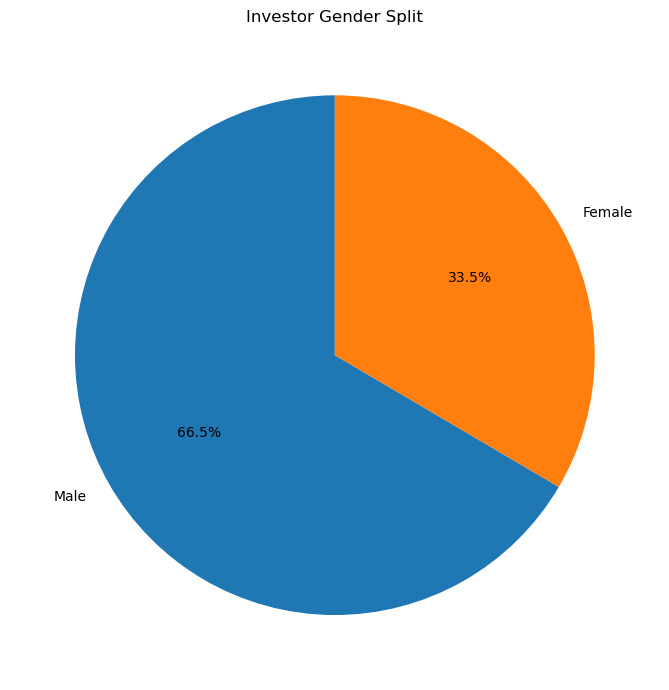

In [77]:
gender_counts = transactions_df["gender"].value_counts()

fig, ax = plt.subplots(figsize=(7, 7))

ax.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

ax.set_title("Investor Gender Split")

plt.tight_layout()

fig.savefig(
    "../Reports/investor_gender_split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

task 6

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

sip_transactions = transactions_df[
    transactions_df["transaction_type"] == "SIP"
].copy()

state_sip = (
    sip_transactions
    .groupby("state")["amount_inr"]
    .sum()
    .sort_values(ascending=True)
)

print(state_sip)

state
Maharashtra       16445629
Rajasthan         16544233
Delhi             17113608
West Bengal       17495769
Uttar Pradesh     17534858
Karnataka         17696903
Haryana           18176696
Gujarat           18378904
Tamil Nadu        18404368
Telangana         18620216
Punjab            20140064
Madhya Pradesh    20682243
Name: amount_inr, dtype: int64


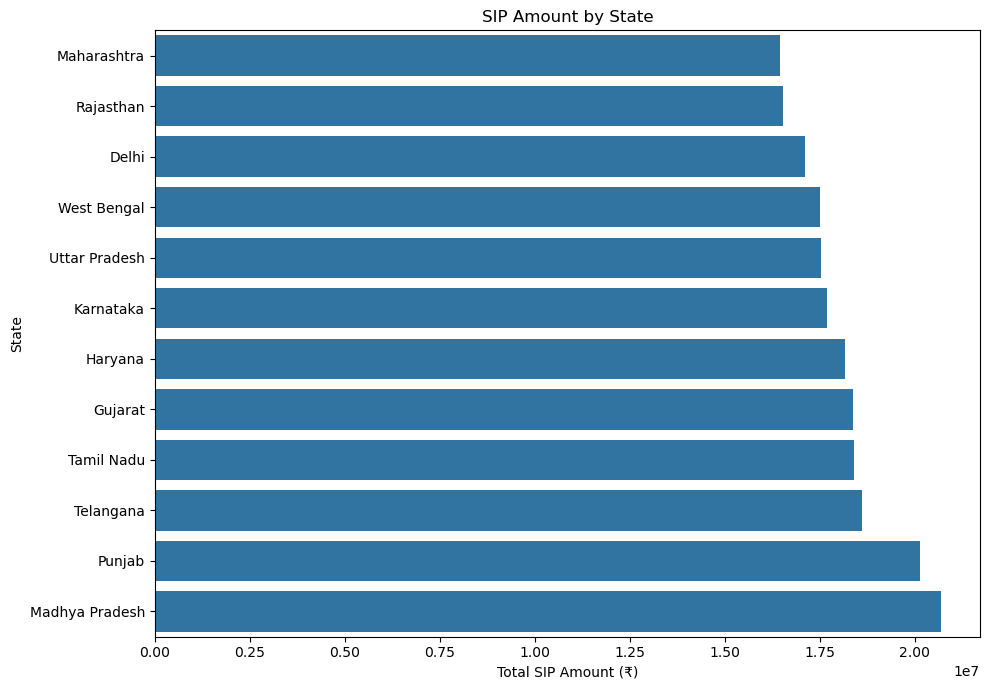

In [79]:
fig, ax = plt.subplots(figsize=(10, 7))

sns.barplot(
    x=state_sip.values,
    y=state_sip.index,
    ax=ax
)

ax.set_title("SIP Amount by State")
ax.set_xlabel("Total SIP Amount (₹)")
ax.set_ylabel("State")

plt.tight_layout()
plt.show()

In [80]:
city_tier_sip = (
    sip_transactions
    .groupby("city_tier")["amount_inr"]
    .sum()
)

print(city_tier_sip)

city_tier
B30     72304870
T30    144928621
Name: amount_inr, dtype: int64


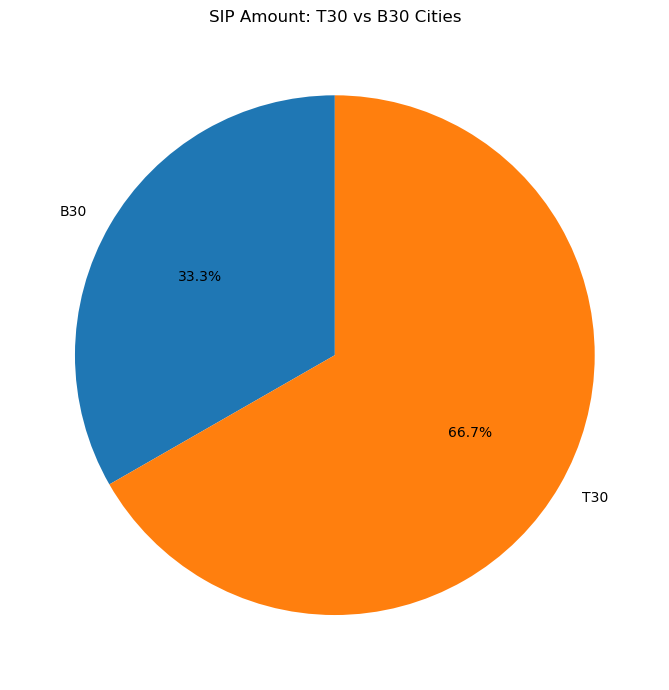

In [81]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.pie(
    city_tier_sip.values,
    labels=city_tier_sip.index,
    autopct="%1.1f%%",
    startangle=90
)

ax.set_title("SIP Amount: T30 vs B30 Cities")

plt.tight_layout()
plt.show()

task 7

In [83]:
import pandas as pd

folio_count_df = pd.read_csv(
    "../data/raw/1788499985036-da4a0c4a-06_industry_folio_count.csv"
)

print("Shape:", folio_count_df.shape)
print("\nColumns:")
print(folio_count_df.columns)

print("\nFirst 5 rows:")
display(folio_count_df.head())

print("\nLast 5 rows:")
display(folio_count_df.tail())

Shape: (21, 6)

Columns:
Index(['month', 'total_folios_crore', 'equity_folios_crore',
       'debt_folios_crore', 'hybrid_folios_crore', 'others_folios_crore'],
      dtype='object')

First 5 rows:


,month,total_folios_crore,equity_folios_crore,debt_folios_crore,hybrid_folios_crore,others_folios_crore
0,2022-01,13.26,9.28,1.86,0.80,1.33
1,2022-04,13.91,9.74,1.95,0.83,1.39
2,2022-07,13.85,9.69,1.94,0.83,1.38
3,2022-10,14.12,9.88,1.98,0.85,1.41
4,2023-01,14.81,10.37,2.07,0.89,1.48



Last 5 rows:


,month,total_folios_crore,equity_folios_crore,debt_folios_crore,hybrid_folios_crore,others_folios_crore
16,2025-07,24.57,17.20,3.44,1.47,2.46
17,2025-08,24.89,17.42,3.48,1.49,2.49
18,2025-09,25.19,17.63,3.53,1.51,2.52
19,2025-10,25.60,17.92,3.58,1.54,2.56
20,2025-12,26.12,18.28,3.66,1.57,2.61


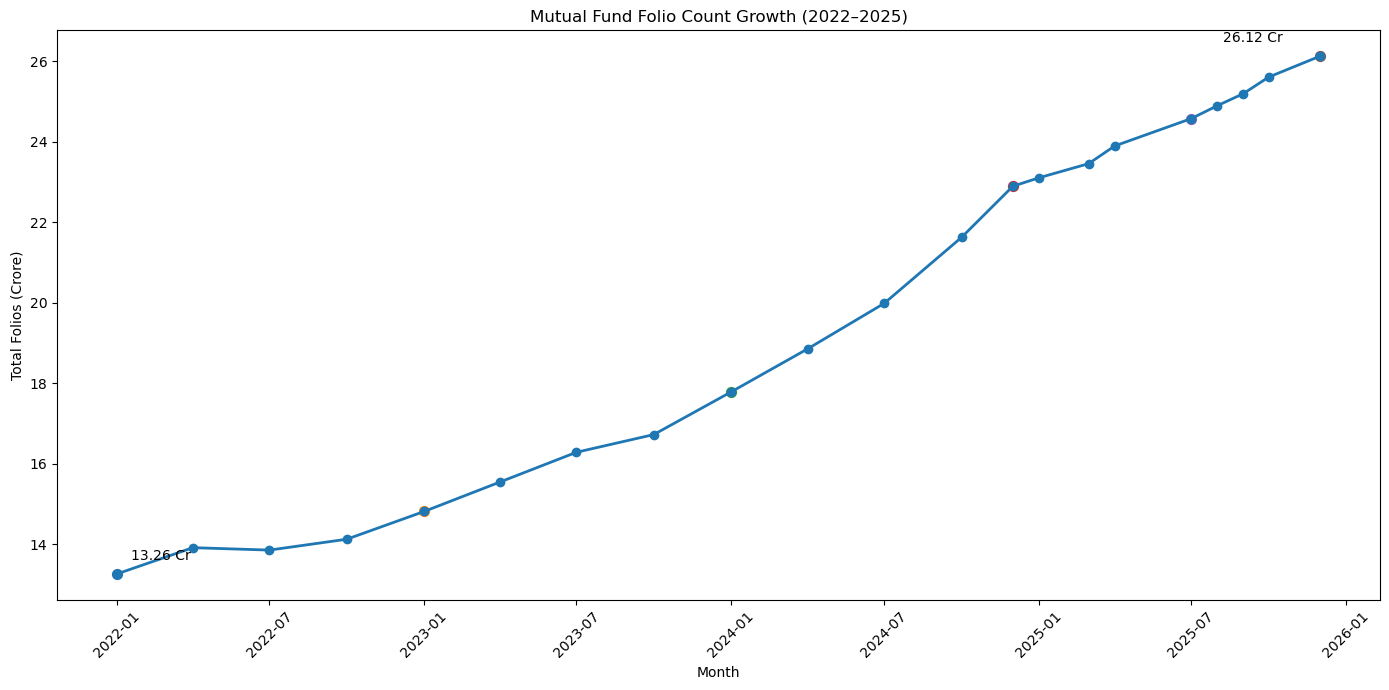

In [84]:
import pandas as pd
import matplotlib.pyplot as plt

folio_count_df["month"] = pd.to_datetime(
    folio_count_df["month"],
    format="%Y-%m"
)

fig, ax = plt.subplots(figsize=(14, 7))

ax.plot(
    folio_count_df["month"],
    folio_count_df["total_folios_crore"],
    marker="o",
    linewidth=2
)

# Mark starting point
start_row = folio_count_df.iloc[0]

ax.annotate(
    f"{start_row['total_folios_crore']:.2f} Cr",
    xy=(start_row["month"], start_row["total_folios_crore"]),
    xytext=(10, 10),
    textcoords="offset points"
)

# Mark ending point
end_row = folio_count_df.iloc[-1]

ax.annotate(
    f"{end_row['total_folios_crore']:.2f} Cr",
    xy=(end_row["month"], end_row["total_folios_crore"]),
    xytext=(-70, 10),
    textcoords="offset points"
)

# Mark key milestones
milestones = folio_count_df.iloc[[0, 4, 8, 12, 16, 20]]

for _, row in milestones.iterrows():
    ax.scatter(
        row["month"],
        row["total_folios_crore"],
        s=50
    )

ax.set_title("Mutual Fund Folio Count Growth (2022–2025)")
ax.set_xlabel("Month")
ax.set_ylabel("Total Folios (Crore)")

ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

task 8

In [85]:
# Select 10 funds
selected_funds = nav_df["amfi_code"].drop_duplicates().head(10).tolist()

print("Selected AMFI codes:")
print(selected_funds)

Selected AMFI codes:
[100016, 100025, 100033, 101206, 101207, 101208, 102885, 102886, 102887, 118632]


In [88]:
# Calculate daily returns for each fund
nav_df = nav_df.sort_values(["amfi_code", "date"]).copy()

nav_df["previous_nav"] = (
    nav_df.groupby("amfi_code")["nav"].shift(1)
)

nav_df["daily_return"] = (
    nav_df["nav"] / nav_df["previous_nav"] - 1
)

print(nav_df[["amfi_code", "date", "nav", "daily_return"]].head(10))

   amfi_code        date       nav  daily_return
0     100016  2022-01-03  520.4608           NaN
1     100016  2022-01-04  515.0971     -0.010306
2     100016  2022-01-05  521.7239      0.012865
3     100016  2022-01-06  515.7880     -0.011377
4     100016  2022-01-07  515.1639     -0.001210
5     100016  2022-01-10  510.7136     -0.008639
6     100016  2022-01-11  513.5542      0.005562
7     100016  2022-01-12  512.3195     -0.002404
8     100016  2022-01-13  510.2445     -0.004050
9     100016  2022-01-14  514.3636      0.008073


In [89]:
# Create table with dates as rows and funds as columns
return_data = nav_df[
    nav_df["amfi_code"].isin(selected_funds)
].pivot(
    index="date",
    columns="amfi_code",
    values="daily_return"
)

# Calculate pairwise correlation
correlation_matrix = return_data.corr()

print("Correlation matrix shape:", correlation_matrix.shape)
display(correlation_matrix)

Correlation matrix shape: (10, 10)


amfi_code,100016,100025,100033,101206,101207,101208,102885,102886,102887,118632
amfi_code,,,,,,,,,,
100016,1.000000,0.045567,-0.000006,0.027747,0.016053,-0.033773,-0.093533,-0.005867,-0.023316,-0.026781
100025,0.045567,1.000000,0.002150,0.023769,-0.006710,0.018455,-0.001038,0.013754,-0.005648,-0.014166
100033,-0.000006,0.002150,1.000000,-0.018079,0.000351,0.007864,-0.034228,-0.018166,-0.036647,-0.013318
101206,0.027747,0.023769,-0.018079,1.000000,0.010202,-0.027230,0.001570,0.007229,-0.006490,-0.005432
101207,0.016053,-0.006710,0.000351,0.010202,1.000000,-0.007530,-0.005929,0.004860,0.002304,0.043384
101208,-0.033773,0.018455,0.007864,-0.027230,-0.007530,1.000000,-0.001436,0.014307,0.036547,0.003507
102885,-0.093533,-0.001038,-0.034228,0.001570,-0.005929,-0.001436,1.000000,0.020691,-0.036704,-0.000285
102886,-0.005867,0.013754,-0.018166,0.007229,0.004860,0.014307,0.020691,1.000000,-0.007865,-0.039886
102887,-0.023316,-0.005648,-0.036647,-0.006490,0.002304,0.036547,-0.036704,-0.007865,1.000000,0.001248


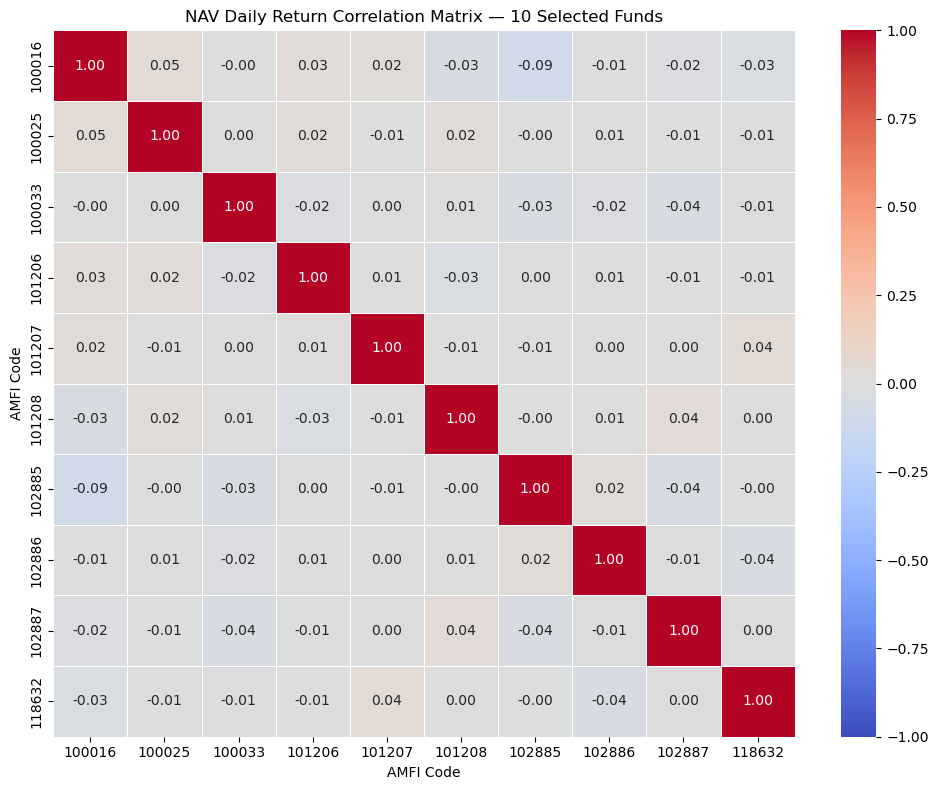

In [90]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    ax=ax
)

ax.set_title("NAV Daily Return Correlation Matrix — 10 Selected Funds")
ax.set_xlabel("AMFI Code")
ax.set_ylabel("AMFI Code")

plt.tight_layout()
plt.show()

task 9

In [91]:
portfolio_holdings_df = pd.read_csv(
    "../data/raw/1788499982117-e3d6ab98-09_portfolio_holdings.csv"
)

print("Shape:", portfolio_holdings_df.shape)

print("\nColumns:")
print(portfolio_holdings_df.columns)

print("\nFirst 5 rows:")
display(portfolio_holdings_df.head())

Shape: (322, 8)

Columns:
Index(['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct',
       'market_value_cr', 'current_price_inr', 'portfolio_date'],
      dtype='object')

First 5 rows:


,amfi_code,stock_symbol,stock_name,sector,weight_pct,market_value_cr,current_price_inr,portfolio_date
0,119551,POWERGRID,Power Grid Corporation,Utilities,13.85,737.09,6011.08,2025-12-31
1,119551,HDFCBANK,HDFC Bank Ltd,Banking,11.19,88.97,1074.65,2025-12-31
2,119551,GRASIM,Grasim Industries Ltd,Diversified,9.90,208.45,5964.59,2025-12-31
3,119551,DRREDDY,Dr. Reddy's Laboratories,Pharma,4.76,161.32,3748.82,2025-12-31
4,119551,ASIANPAINT,Asian Paints Ltd,Paints,10.25,725.90,1321.45,2025-12-31


In [92]:
sector_allocation = (
    portfolio_holdings_df
    .groupby("sector")["weight_pct"]
    .sum()
    .sort_values(ascending=False)
)

print(sector_allocation)

sector
Banking           652.26
IT                455.47
Pharma            407.45
Automobile        323.65
Utilities         265.54
FMCG              229.11
Infrastructure    192.16
Diversified       169.23
Telecom           145.62
Consumer Goods    127.61
NBFC              119.09
Energy            117.91
Cement            105.03
Paints             89.86
Name: weight_pct, dtype: float64


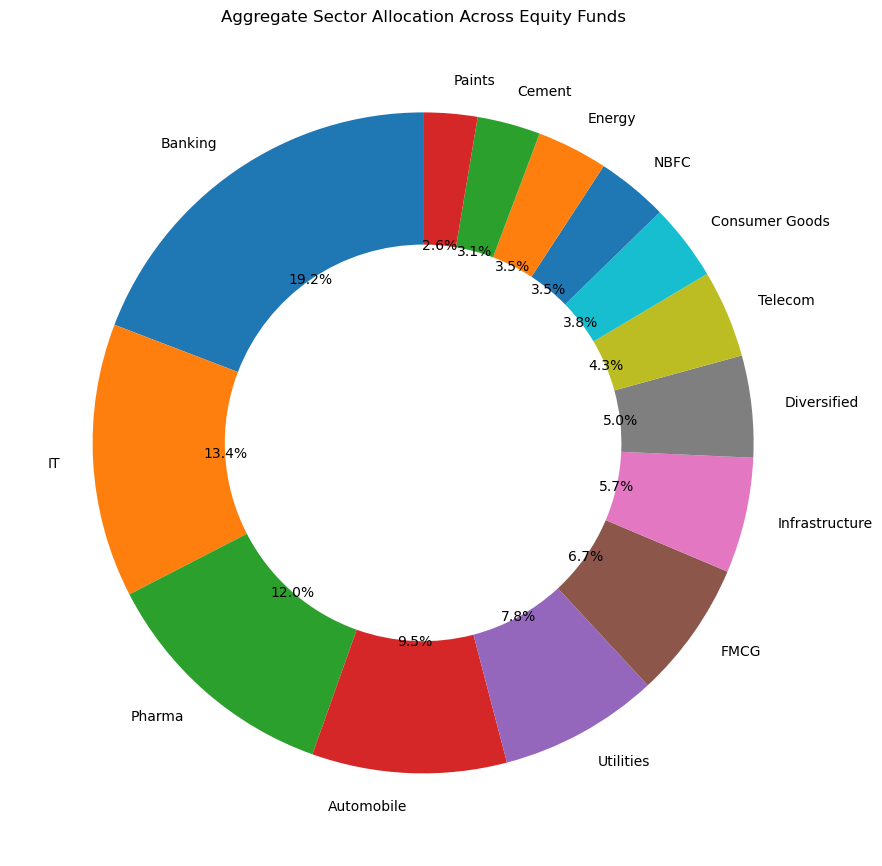

In [93]:
fig, ax = plt.subplots(figsize=(9, 9))

ax.pie(
    sector_allocation.values,
    labels=sector_allocation.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops=dict(width=0.4)
)

ax.set_title("Aggregate Sector Allocation Across Equity Funds")

plt.tight_layout()
plt.show()

task 10

# 10 Key EDA Findings

1. The daily NAV trends of the 40 mutual fund schemes show different performance patterns across the 2022–2026 period, with 2023 highlighted as the bull-run period and 2024 as the market-correction period.  
   **Supporting chart:** Daily NAV Trend of 40 Mutual Fund Schemes.

2. AUM distribution varies across fund houses between 2022 and 2025, with SBI highlighted as having ₹12.5 lakh crore of AUM dominance.  
   **Supporting chart:** AUM Growth by Fund House (2022–2025).

3. Monthly SIP inflows show an overall upward trend across the analysis period and reach an all-time high of ₹31,002 crore in December 2025.  
   **Supporting chart:** Monthly SIP Inflow Trend.

4. Net inflows vary across fund categories and months, with the heatmap showing periods of positive and negative category-level inflows.  
   **Supporting chart:** Category-wise Net Inflow Heatmap.

5. The largest investor age-group segment in the transaction data is the 26–35 age group.  
   **Supporting chart:** Investor Age Group Distribution.

6. SIP transaction amounts vary across age groups, with the box plot showing differences in the distribution and spread of SIP amounts.  
   **Supporting chart:** SIP Amount Distribution by Age Group.

7. SIP investment amounts are distributed across multiple Indian states, with the horizontal bar chart showing differences in total SIP amounts by state.  
   **Supporting chart:** SIP Amount by State.

8. Total folios increased from 13.26 crore in January 2022 to 26.12 crore in December 2025, indicating substantial growth over the analysis period.  
   **Supporting chart:** Mutual Fund Folio Count Growth.

9. The correlation heatmap shows the pairwise relationship between daily returns of the 10 selected mutual fund schemes.  
   **Supporting chart:** NAV Daily Return Correlation Matrix.

10. The aggregate portfolio holdings show the distribution of investments across different sectors, with sector weights varying across the equity-fund holdings.  
    **Supporting chart:** Aggregate Sector Allocation Across Equity Funds.